# Ensemble Model Evaluation — Sample Signals

Loads the saved model bundles (RandomForest, XGBoost, LightGBM, Logistic Regression),
scores a batch of new/unseen signals, and builds a ranked Top-N portfolio.

**New in this version:**
- Explicit **Surge / No Surge** label alongside the raw probability
- Optional **industry filter** to restrict scoring to specific industries
- **Per-ticker feature drivers** (SHAP) — which features pushed each of the
  day's Top-5 ranked tickers toward/away from a surge prediction

Requires the `shap` package: `pip install shap`


In [1]:
# Run this in a new cell then restart kernel
!pip install --upgrade numpy scipy adjustText
!pip install "numpy>=2.0.0,<2.3.0" "scipy>=1.14.0" "adjustText>=1.0.0"

  Using cached numpy-2.5.4-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
Using cached numpy-2.5.4-cp312-cp312-win_amd64.whl (12.6 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.3.5
    Uninstalling numpy-2.3.5:
      Successfully uninstalled numpy-2.3.5


  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.5.4 which is incompatible.
gensim 4.3.3 requires scipy<1.14.0,>=1.7.0, but you have scipy 1.18.1 which is incompatible.
mlxtend 0.24.0 requires pandas>=2.3.3, but you have pandas 2.2.3 which is incompatible.
mlxtend 0.24.0 requires scikit-learn>=1.8.0, but you have scikit-learn 1.6.1 which is incompatible.
numba 0.66.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.4 which is incompatible.
streamlit 1.37.1 requires packaging<25,>=20, but you have packaging 26.3 which is incompatible.
streamlit 1.37.1 requires pillow<11,>=7.1.0, but you have pillow 12.3.0 which is incompatible.
streamlit 1.37.1 requires p

  Using cached numpy-2.2.6-cp312-cp312-win_amd64.whl.metadata (60 kB)
Using cached numpy-2.2.6-cp312-cp312-win_amd64.whl (12.6 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.4
    Uninstalling numpy-2.5.4:
      Successfully uninstalled numpy-2.5.4


  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.2.6 which is incompatible.
gensim 4.3.3 requires scipy<1.14.0,>=1.7.0, but you have scipy 1.18.1 which is incompatible.
mlxtend 0.24.0 requires numpy>=2.3.5, but you have numpy 2.2.6 which is incompatible.
mlxtend 0.24.0 requires pandas>=2.3.3, but you have pandas 2.2.3 which is incompatible.
mlxtend 0.24.0 requires scikit-learn>=1.8.0, but you have scikit-learn 1.6.1 which is incompatible.
streamlit 1.37.1 requires packaging<25,>=20, but you have packaging 26.3 which is incompatible.
streamlit 1.37.1 requires pillow<11,>=7.1.0, but you have pillow 12.3.0 which is incompatible.
streamlit 1.37.1 requires pro

In [2]:
import ast
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pygsheets
import shap  # pip install shap

from sklearn.preprocessing import StandardScaler
from sklearn.impute        import SimpleImputer
from sklearn.pipeline      import Pipeline
from sklearn.compose       import ColumnTransformer


In [3]:
# ══════════════════════════════════════════════════════════════════════════════
# STEP 1 — Load the ENSEMBLE bundle (RandomForest + XGBoost + LightGBM + Logistic Regression)
# ══════════════════════════════════════════════════════════════════════════════
MODEL_DIR = r"C:\Users\Segun\Desktop\Model mangement\Classification model\5 days prediction model\NGX v1"

MODEL_PATHS = {
    "ngxRandomForest_ensemble_v1":       rf"{MODEL_DIR}\ngxRandomForest_ensemble_v1.pkl",
    "ngxXGBoost_ensemble_v1":            rf"{MODEL_DIR}\ngxXGBoost_ensemble_v1.pkl",
    "ngxLightGBM_ensemble_v1":           rf"{MODEL_DIR}\ngxLightGBM_ensemble_v1.pkl",
    "ngxLogisticRegression_ensemble_v1": rf"{MODEL_DIR}\ngxLogisticRegression_ensemble_v1.pkl",
}

loaded_models = {}
ALL_FEATURES         = None
NUMERIC_FEATURES     = None
CATEGORICAL_FEATURES = None
USE_ENSEMBLE          = True   # average all loaded models — set False to use only best_single_name
best_single_name      = None

for model_name, path in MODEL_PATHS.items():
    bundle = joblib.load(path)
    loaded_models[model_name] = bundle["model"]

    # Features should be identical across all bundles — keep the last one loaded
    ALL_FEATURES         = bundle["all_features"]
    NUMERIC_FEATURES     = bundle["numeric_features"]
    CATEGORICAL_FEATURES = bundle["categorical_features"]

    if "best_single_name" in bundle:
        best_single_name = bundle["best_single_name"]

    print(f"Loaded ✓  {model_name:20s}  →  {type(bundle['model'])}")
    assert hasattr(bundle["model"], "predict_proba"), f"{model_name} is not a valid model"

print(f"\nAll features : {len(ALL_FEATURES)}")
print(f"Mode         : {'ENSEMBLE (avg of all loaded models)' if USE_ENSEMBLE else best_single_name}")
print("Ready to predict ✓")


def predict_proba_ensemble(X_input):
    """Average predicted probability across all loaded models."""
    if USE_ENSEMBLE:
        return np.mean(
            [model.predict_proba(X_input)[:, 1] for model in loaded_models.values()],
            axis=0,
        )
    else:
        return loaded_models[best_single_name].predict_proba(X_input)[:, 1]


Loaded ✓  ngxRandomForest_ensemble_v1  →  <class 'sklearn.pipeline.Pipeline'>
Loaded ✓  ngxXGBoost_ensemble_v1  →  <class 'sklearn.pipeline.Pipeline'>
Loaded ✓  ngxLightGBM_ensemble_v1  →  <class 'sklearn.pipeline.Pipeline'>
Loaded ✓  ngxLogisticRegression_ensemble_v1  →  <class 'sklearn.pipeline.Pipeline'>

All features : 190
Mode         : ENSEMBLE (avg of all loaded models)
Ready to predict ✓



  ngxRandomForest_ensemble_v1 — Top 20 features (timeframes aggregated)
base_group
Volatility.W                  0.070709
Volatility.D                  0.066337
volume_change|1W              0.057670
Volatility.M                  0.055512
volume_change|1M              0.048293
MoneyFlow                     0.046785
MoneyFlow|1M                  0.043607
market_cap_basic              0.039405
PatternScore                  0.036626
MoneyFlow|30                  0.031885
volume_change                 0.031533
volume_change|1               0.030249
Candle.Marubozu.White         0.028674
MoneyFlow|1W                  0.028158
VWAP|1M                       0.027777
relative_volume_intraday|5    0.025747
MoneyFlow|5                   0.024620
MoneyFlow|1                   0.023606
volume_change|15              0.023456
MoneyFlow|15                  0.022876

  ngxXGBoost_ensemble_v1 — Top 20 features (timeframes aggregated)
base_group
Candle.Doji.Dragonfly                         0.101878
Ca

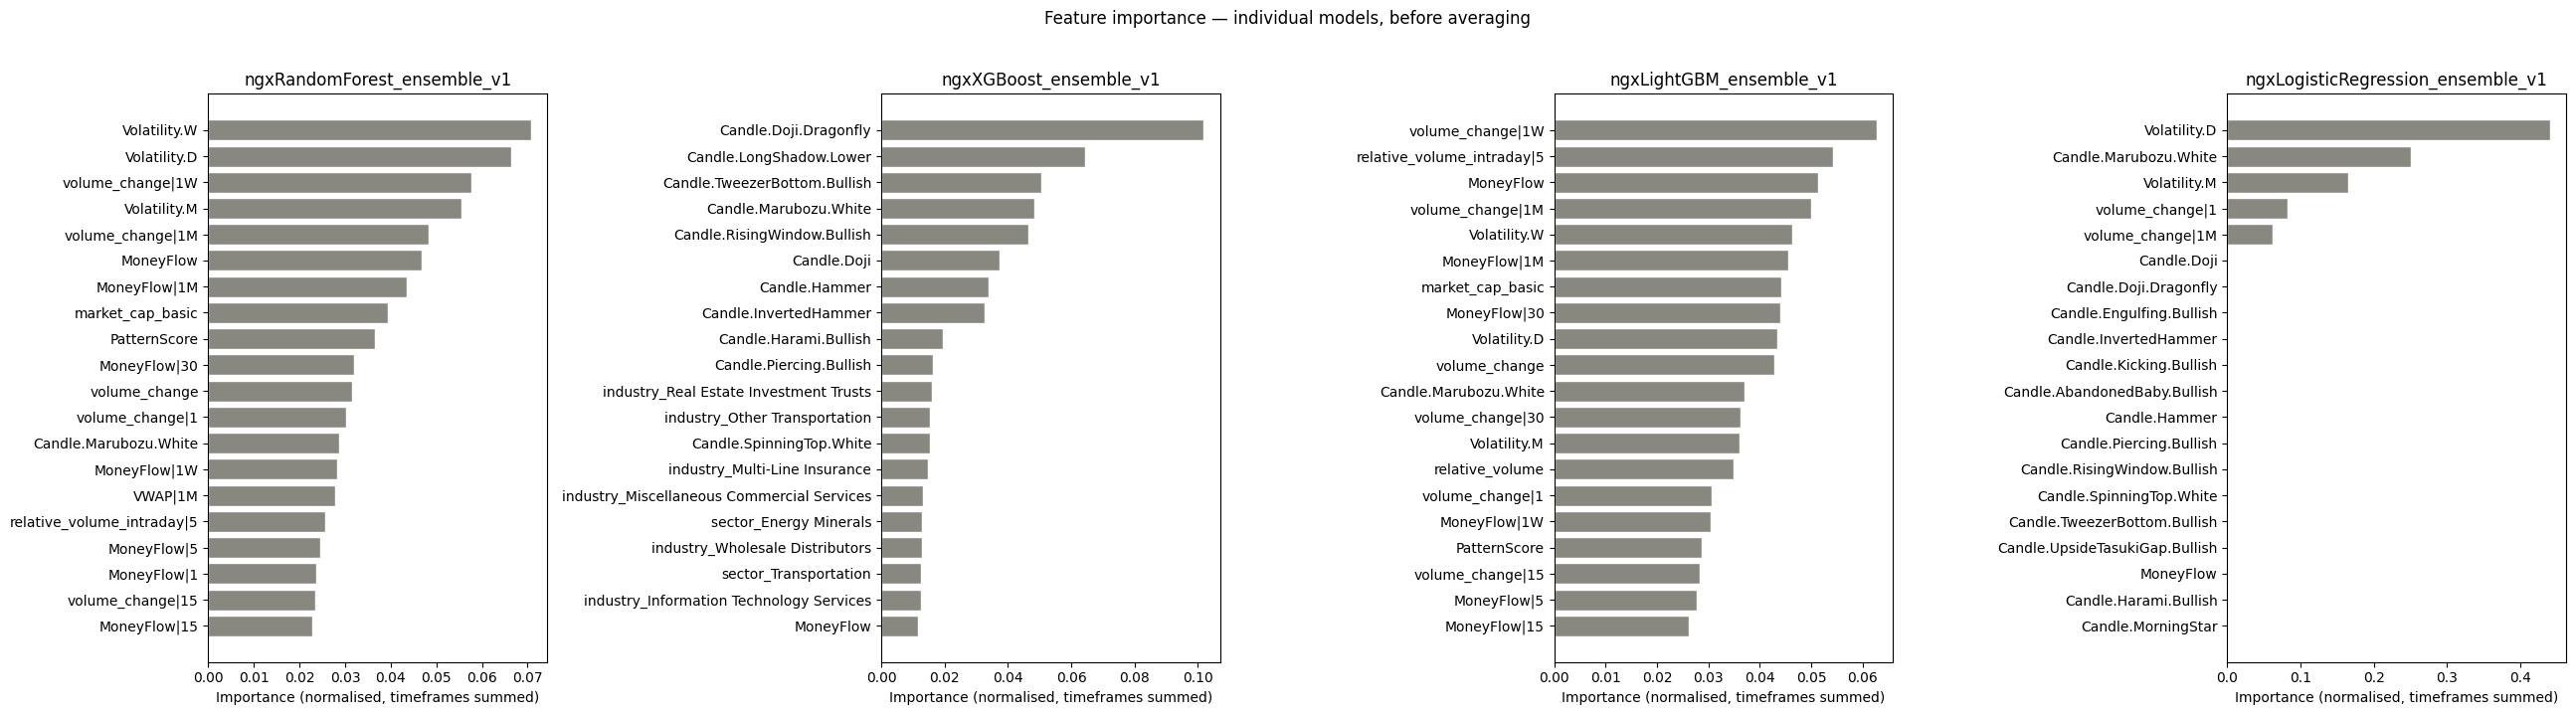


All models side by side (top 20, sorted by average):
                             ngxRandomForest_ensemble_v1  ngxXGBoost_ensemble_v1  ngxLightGBM_ensemble_v1  ngxLogisticRegression_ensemble_v1  avg_importance
base_group                                                                                                                                                  
Volatility.D                                    0.066337                0.009690                 0.043421                           0.440674        0.140030
Candle.Marubozu.White                           0.028674                0.048404                 0.037066                           0.250593        0.091184
Volatility.M                                    0.055512                0.009963                 0.036007                           0.164630        0.066528
volume_change|1M                                0.048293                0.008609                 0.050040                           0.061631        0.042143
volu

In [4]:
# ══════════════════════════════════════════════════════════════════════════════
# FEATURE IMPORTANCE — per individual model, BEFORE averaging (GLOBAL importance)
# ══════════════════════════════════════════════════════════════════════════════
feat_names = NUMERIC_FEATURES + CATEGORICAL_FEATURES

def get_base_pattern(col_name: str) -> str:
    if col_name.startswith("pattern_"):
        return col_name.replace("pattern_", "").split("|")[0]
    return col_name

def get_model_importance(pipeline, feature_names):
    """Handles both tree models (feature_importances_) and linear models (coef_)."""
    model = pipeline.named_steps["model"]
    if hasattr(model, "feature_importances_"):
        raw = np.asarray(model.feature_importances_, dtype=float)
    elif hasattr(model, "coef_"):
        raw = np.abs(np.asarray(model.coef_[0], dtype=float))
    else:
        return None
    total = raw.sum()
    raw = raw / total if total > 0 else raw
    return pd.Series(raw, index=feature_names)

base_grouped_by_model = {}

for name, bundle_model in loaded_models.items():
    fi_norm = get_model_importance(bundle_model, feat_names)
    if fi_norm is None:
        continue

    fi_df = fi_norm.reset_index()
    fi_df.columns = ["Feature", "Importance"]
    fi_df["base_group"] = fi_df["Feature"].apply(get_base_pattern)

    base_grouped = (fi_df.groupby("base_group")["Importance"]
                       .sum()
                       .sort_values(ascending=False))
    base_grouped_by_model[name] = base_grouped

    print(f"\n{'='*55}")
    print(f"  {name} — Top 20 features (timeframes aggregated)")
    print(f"{'='*55}")
    print(base_grouped.head(20).to_string())

# ── Side-by-side charts, one per model ─────────────────────────────────────────
n_models = len(base_grouped_by_model)
fig, axes = plt.subplots(1, n_models, figsize=(6.5 * n_models, 7))
if n_models == 1:
    axes = [axes]
colors = {"RandomForest": "#185FA5", "XGBoost": "#1D9E75", "LightGBM": "#D85A30",
          "LogisticRegression": "#8E5FB5"}

for ax, (name, base_grouped) in zip(axes, base_grouped_by_model.items()):
    top20 = base_grouped.head(20)
    ax.barh(top20.index[::-1], top20.values[::-1],
            color=colors.get(name, "#888780"), edgecolor="white")
    ax.set_title(name)
    ax.set_xlabel("Importance (normalised, timeframes summed)")

plt.suptitle("Feature importance — individual models, before averaging", y=1.02)
plt.tight_layout()
plt.show()

# ── Combined table — all models side by side, sortable ─────────────────────────
combined_individual = pd.DataFrame(base_grouped_by_model).fillna(0)
combined_individual["avg_importance"] = combined_individual.mean(axis=1)
combined_individual = combined_individual.sort_values("avg_importance", ascending=False)

print("\nAll models side by side (top 20, sorted by average):")
print(combined_individual.head(20).to_string())


In [5]:
# ══════════════════════════════════════════════════════════════════════════════
# STEP 2 — Load new signals (same cleaning as the training notebook)
# ══════════════════════════════════════════════════════════════════════════════
SERVICE_ACCOUNT_FILE   = r"C:\Users\Segun\Desktop\wqu-satellite-image-learning1-175e0a0906aa.json"
SHEET_URL              = "https://docs.google.com/spreadsheets/d/1jkbrrHnR48JztVz0SrqZELKjOenVm44wsiIchLW0K9g/edit#gid=1868316212"
SAMPLE_WORKSHEET_INDEX = 4 #4 ngx ,8,3 jse    # ← confirm this is the tab holding your unseen/incoming signals
TIME_COL               = "time"
TICKER_COL             = "name"
SAMPLE_TEST_START      = "2026-10-19"
SAMPLE_TEST_END        = "2026-10-27"

# ── Industry selection (optional filter) ────────────────────────────────────────
# Set to None to include all industries. Otherwise pass a list of exact industry
# names as they appear in your sheet's "industry" column, e.g.:
#   INDUSTRY_FILTER = ["Software - Application", "Biotechnology"]
INDUSTRY_FILTER = None

# ── Decision threshold for the Surge / No Surge label ──────────────────────────
# Default 0.5 is a placeholder — if your validation work showed the model's
# probabilities are compressed into a narrow range (common with few positive
# training examples), swap this for whatever threshold your precision/recall
# or return-vs-threshold analysis actually supported.
DECISION_THRESHOLD = 0.48

# Load sheet
gc        = pygsheets.authorize(service_account_file=SERVICE_ACCOUNT_FILE)
sh        = gc.open_by_url(SHEET_URL)
wks       = sh[SAMPLE_WORKSHEET_INDEX]
df_sample = wks.get_as_df()

# Clean
df_sample = df_sample.loc[:, ~df_sample.columns.duplicated(keep="first")]
df_sample = df_sample[[c for c in df_sample.columns if str(c).strip() != ""]]
df_sample = df_sample.replace("", np.nan).dropna(how="all").reset_index(drop=True)

# Parse datetime
df_sample[TIME_COL] = (
    pd.to_datetime(df_sample[TIME_COL], utc=True, errors="coerce")
      .dt.tz_convert("America/New_York")
      .dt.tz_localize(None)
)

# Coerce numerics
skip_text = {TIME_COL, TICKER_COL, "sector", "industry", "BreakoutPatterns"}
for col in df_sample.columns:
    if col not in skip_text and isinstance(df_sample[col], pd.Series):
        converted = pd.to_numeric(df_sample[col], errors="coerce")
        if converted.notna().sum() > 0:
            df_sample[col] = converted

df_sample = df_sample.sort_values(TIME_COL).reset_index(drop=True)

if "industry" in df_sample.columns:
    print("Available industries in this batch:")
    print(df_sample["industry"].value_counts().to_string())
else:
    print("No 'industry' column found in this sheet — INDUSTRY_FILTER will have no effect.")


C:\Users\Segun\AppData\Local\Temp\ipykernel_26292\4244582481.py:34: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_sample = df_sample.replace("", np.nan).dropna(how="all").reset_index(drop=True)


Available industries in this batch:
industry
Multi-Line Insurance                 272
Regional Banks                       265
Agricultural Commodities/Milling     244
Pharmaceuticals: Major               155
Electrical Products                  126
Major Banks                           87
Property/Casualty Insurance           71
Investment Banks/Brokers              69
Investment Managers                   69
Beverages: Alcoholic                  65
Insurance Brokers/Services            59
Hotels/Resorts/Cruise lines           51
Life/Health Insurance                 45
Other Transportation                  43
Real Estate Development               43
Information Technology Services       41
Oil Refining/Marketing                39
Finance/Rental/Leasing                39
Food: Major Diversified               39
Miscellaneous Commercial Services     37
Movies/Entertainment                  36
Wireless Telecommunications           36
Construction Materials                32
Air Freight/

In [6]:
df_sample

,name,BreakoutPatterns,PatternScore,sector,industry,close,time,VWAP,VWAP|1,VWAP|5,...,volume_change|1M,relative_volume,relative_volume_intraday|5,MoneyFlow,MoneyFlow|1,MoneyFlow|5,MoneyFlow|15,MoneyFlow|30,MoneyFlow|1W,MoneyFlow|1M
0,CORNERST,"['Candle.Doji.Dragonfly|1W', 'Candle.LongShado...",74.5,Finance,Multi-Line Insurance,5.85,2026-05-26 05:00:00,5.700000,5.476586,5.476586,...,-17.927806,1.021550,3.527535,57.275776,65.035272,61.221734,61.221734,61.221734,51.595691,7.532063
1,LEARNAFRCA,"['Candle.Doji.Dragonfly', 'Candle.Doji.Dragonf...",74.5,Consumer Services,Publishing: Books/Magazines,12.75,2026-05-26 05:00:00,12.466667,12.481067,12.481067,...,709.781694,0.755392,0.878468,55.865902,62.621759,69.176437,69.176437,69.176437,58.425859,87.714522
2,JAIZBANK,"['Candle.Doji.Dragonfly|5', 'Candle.Doji.Drago...",74.5,Finance,Major Banks,9.15,2026-05-26 05:00:00,9.120000,9.121686,9.114974,...,4.253631,0.465907,0.450258,52.491532,52.580618,39.954439,48.535568,32.783414,39.236509,53.116874
3,REGALINS,"['Candle.Doji.Dragonfly', 'Candle.LongShadow.L...",74.5,Finance,Property/Casualty Insurance,1.07,2026-05-26 05:00:00,1.063333,1.054952,1.054952,...,43.275172,0.767145,3.788172,52.307487,1.945659,3.263432,2.352425,1.667025,47.622993,82.952094
4,NSLTECH,"['Candle.Doji.Dragonfly', 'Candle.LongShadow.L...",74.5,Consumer Services,Movies/Entertainment,0.89,2026-05-26 05:00:00,0.883333,0.876959,0.876959,...,26.282821,0.371949,0.258418,50.224767,69.208984,68.973863,62.909738,61.442322,19.831073,50.716262
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2347,NNFM,"['Candle.Marubozu.White|5', 'Candle.Marubozu.W...",65.0,Process Industries,Agricultural Commodities/Milling,79.40,2026-10-27 05:00:00,79.400000,75.929335,77.616667,...,-58.018440,2.403948,1.168242,47.945205,22.254135,37.189753,37.189753,37.189753,436.363636,42.138014
2348,WEMABANK,"['Candle.Marubozu.White', 'Candle.Marubozu.Whi...",65.0,Finance,Regional Banks,31.10,2026-10-27 05:00:00,30.716667,30.200061,30.200061,...,-20.954690,1.567481,1.017694,75.014617,41.366889,42.561512,49.652291,46.876664,61.772991,87.780067
2349,VFDGROUP,"['Candle.Marubozu.White', 'Candle.Marubozu.Whi...",65.0,Finance,Investment Managers,12.40,2026-10-27 05:00:00,12.316667,12.345000,12.345000,...,-85.534227,0.681328,0.443153,53.826777,95.410656,95.494895,94.580197,96.028879,86.164671,55.892307
2350,DANGCEM,"['Candle.Marubozu.White|1W', 'Candle.RisingWin...",63.5,Non-Energy Minerals,Construction Materials,1341.90,2026-10-27 05:00:00,1341.266667,1010.000000,1010.000000,...,-1.377774,2.851659,0.652747,97.272942,66.583496,82.359799,83.775980,89.478525,91.365382,84.810417


In [7]:
# ══════════════════════════════════════════════════════════════════════════════
# STEP 3 — Apply industry filter + date filter, then encode (must match training)
# ══════════════════════════════════════════════════════════════════════════════
if INDUSTRY_FILTER is not None and "industry" in df_sample.columns:
    before = len(df_sample)
    unknown = [i for i in INDUSTRY_FILTER if i not in df_sample["industry"].unique()]
    if unknown:
        print(f"⚠️  These INDUSTRY_FILTER values weren't found in this batch: {unknown}")
    df_sample = df_sample[df_sample["industry"].isin(INDUSTRY_FILTER)].reset_index(drop=True)
    print(f"Industry filter applied: {before} → {len(df_sample)} rows (kept: {INDUSTRY_FILTER})")

def encode_patterns(df):
    df = df.copy()
    df["BreakoutPatterns"] = df["BreakoutPatterns"].fillna("[]")
    df["BreakoutPatterns"] = df["BreakoutPatterns"].apply(
        lambda x: ast.literal_eval(x) if isinstance(x, str) else []
    )
    exploded = df[["BreakoutPatterns"]].explode("BreakoutPatterns")
    dummies  = pd.get_dummies(exploded["BreakoutPatterns"], prefix="pattern")
    dummies  = dummies.groupby(level=0).max()
    return pd.concat([df.drop(columns=["BreakoutPatterns"]), dummies], axis=1)

def encode_categoricals(df, cols, drop_first=False):
    existing = [c for c in cols if c in df.columns]
    return pd.get_dummies(df, columns=existing, drop_first=drop_first)

# Keep the raw, human-readable sector/industry labels for display & export later
# (one-hot encoding below will replace the original columns with dummy columns)
df_sample_raw = df_sample.copy()

df_sample = encode_patterns(df_sample)
df_sample = encode_categoricals(df_sample, cols=["sector", "industry"], drop_first=False)

# Date filter — applied identically to both the encoded and raw frames so rows stay aligned
mask = (
    (df_sample[TIME_COL].dt.date >= pd.Timestamp(SAMPLE_TEST_START).date()) &
    (df_sample[TIME_COL].dt.date <= pd.Timestamp(SAMPLE_TEST_END).date())
)
df_sample     = df_sample[mask].copy().reset_index(drop=True)
df_sample_raw = df_sample_raw[mask.values].copy().reset_index(drop=True)
print(f"Signals found : {len(df_sample)}")


Signals found : 153


In [8]:
# ══════════════════════════════════════════════════════════════════════════════
# STEP 4 — Predict using the ENSEMBLE (averaged across all loaded models)
# ══════════════════════════════════════════════════════════════════════════════
X_sample = df_sample.reindex(columns=ALL_FEATURES, fill_value=0).copy()
bool_c   = X_sample.select_dtypes(include="bool").columns
X_sample[bool_c] = X_sample[bool_c].astype(int)

# ── Individual model probabilities, for transparency ────────────────────────────
for name, model in loaded_models.items():
    df_sample[f"prob_{name}"] = model.predict_proba(X_sample)[:, 1]

# ── Ensemble (or single-best) probability — used for ranking ──────────────────
df_sample["pred_prob"]   = predict_proba_ensemble(X_sample)
df_sample["pred_label"]  = (df_sample["pred_prob"] >= DECISION_THRESHOLD).astype(int)
df_sample["pred_surge"]  = np.where(df_sample["pred_label"] == 1, "Surge", "No Surge")
df_sample["signal_date"] = df_sample[TIME_COL].dt.date
df_sample["rank"]        = df_sample.groupby("signal_date")["pred_prob"].rank(
                               ascending=False, method="first")

# Bring the human-readable industry/sector labels back in for display/export
if "industry" in df_sample_raw.columns:
    df_sample["industry"] = df_sample_raw["industry"].values
if "sector" in df_sample_raw.columns:
    df_sample["sector"] = df_sample_raw["sector"].values

print(f"Predicted label counts:")
print(df_sample["pred_surge"].value_counts().to_string())

# ── Portfolio Top-N ────────────────────────────────────────────────────────────
TOP_N = 10
portfolio_sample = df_sample[df_sample["rank"] <= TOP_N].sort_values(["signal_date", "rank"])

print(f"\n{'='*70}")
print(f"  PORTFOLIO — Top-{TOP_N} signals per day  "
      f"({'ENSEMBLE' if USE_ENSEMBLE else best_single_name})")
print(f"  {SAMPLE_TEST_START} → {SAMPLE_TEST_END}"
      f"{'  |  Industry filter: ' + str(INDUSTRY_FILTER) if INDUSTRY_FILTER else ''}")
print(f"{'='*70}")

for date, group in portfolio_sample.groupby("signal_date"):
    print(f"\n  📅 {date}")
    for _, r in group.iterrows():
        votes = "  ".join(
            f"{name[:3]}={r.get(f'prob_{name}', float('nan')):.2f}"
            for name in loaded_models
        )
        industry_label = f"  [{r['industry']}]" if "industry" in r and pd.notna(r["industry"]) else ""
        print(f"    #{int(r['rank'])}  {str(r[TICKER_COL]):6s}  "
              f"close=${float(r['close']):.4f}  "
              f"ENSEMBLE_prob={r['pred_prob']:.3f}  →  {r['pred_surge']:<8s}"
              f"{industry_label}  "
              f"[{votes}]  "
              f"PatternScore={r.get('PatternScore', '?')}")


C:\Users\Segun\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Segun\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Predicted label counts:
pred_surge
No Surge    153

  PORTFOLIO — Top-10 signals per day  (ENSEMBLE)
  2026-10-19 → 2026-10-27

  📅 2026-10-19
    #1  INTENEGINS  close=$2.0200  ENSEMBLE_prob=0.305  →  No Surge  [Life/Health Insurance]  [ngx=0.22  ngx=0.41  ngx=0.00  ngx=0.59]  PatternScore=46.5
    #2  JAPAULGOLD  close=$2.5000  ENSEMBLE_prob=0.303  →  No Surge  [Other Transportation]  [ngx=0.15  ngx=0.41  ngx=0.00  ngx=0.65]  PatternScore=51.5
    #3  THOMASWY  close=$2.6600  ENSEMBLE_prob=0.281  →  No Surge  [Wholesale Distributors]  [ngx=0.18  ngx=0.37  ngx=0.00  ngx=0.57]  PatternScore=54.0
    #4  ETI     close=$68.0000  ENSEMBLE_prob=0.277  →  No Surge  [Investment Banks/Brokers]  [ngx=0.21  ngx=0.41  ngx=0.00  ngx=0.48]  PatternScore=65.0
    #5  JAIZBANK  close=$7.8000  ENSEMBLE_prob=0.240  →  No Surge  [Major Banks]  [ngx=0.12  ngx=0.37  ngx=0.03  ngx=0.44]  PatternScore=65.0
    #6  FIRSTHOLDCO  close=$137.3000  ENSEMBLE_prob=0.237  →  No Surge  [Regional Banks]  [ngx=0.12  

---
## 🔎 Per-Ticker Feature Drivers (Local Importance)

The global feature-importance charts above show what each model relies on
*overall*. They don't tell you why any **one specific ticker** was ranked
highly today. This section uses [SHAP](https://shap.readthedocs.io/) to answer
that — for each of today's **Top-5** ranked tickers, it shows the 5 features
that pushed that specific prediction toward or away from "Surge", signed:
positive = pushed toward Surge, negative = pushed toward No Surge.

**Dummy/one-hot columns are aggregated**: all `pattern_*` columns are combined
into a single **BreakoutPatterns** score, and likewise for `sector_*` →
**Sector** and `industry_*` → **Industry**. Otherwise a one-hot column's
contribution gets diluted across dozens of near-zero individual columns and
would rarely surface in a top-5, even when "which pattern fired" is actually
one of the biggest drivers for that ticker. Where an aggregate group makes the
top-5, a breakdown of its individual active components is printed underneath.

This is a genuinely different (and heavier) computation than the global
importance above — expect it to take longer to run, especially for
RandomForest with many trees.


In [9]:
# ══════════════════════════════════════════════════════════════════════════════
# STEP 5 — Top-5 feature drivers per ticker (SHAP local importance, dummy columns aggregated)
# ══════════════════════════════════════════════════════════════════════════════
EXPLAIN_TOP_N = 10   # explain exactly the top-5 ranked tickers per day (independent of portfolio TOP_N)

# Prefixes that should be collapsed into a single aggregate score instead of
# being spread across dozens of individual one-hot columns.
DUMMY_GROUP_PREFIXES = {
    "pattern_":  "BreakoutPatterns",
    "sector_":   "Sector",
    "industry_": "Industry",
}


def get_base_group(col_name: str) -> str:
    for prefix, label in DUMMY_GROUP_PREFIXES.items():
        if col_name.startswith(prefix):
            return label
    return col_name


def compute_shap_values(pipeline, X_transformed):
    """
    Returns a (n_samples, n_features) SHAP value array for the positive
    ("surge") class.
      - Tree models (RF / XGBoost / LightGBM) -> shap.TreeExplainer
      - Logistic Regression                   -> shap.LinearExplainer
    """
    model = pipeline.named_steps["model"]

    if hasattr(model, "feature_importances_"):
        explainer = shap.TreeExplainer(model)
        raw = explainer.shap_values(X_transformed)
        # Older shap versions return a list [class0_shap, class1_shap] for binary clf
        if isinstance(raw, list):
            raw = raw[1]
        # Newer shap versions may return shape (n, features, 2) for binary clf
        if isinstance(raw, np.ndarray) and raw.ndim == 3:
            raw = raw[:, :, 1]
        return raw

    elif hasattr(model, "coef_"):
        explainer = shap.LinearExplainer(model, X_transformed)
        return explainer.shap_values(X_transformed)

    return None


explain_subset = df_sample[df_sample["rank"] <= EXPLAIN_TOP_N].sort_values(["signal_date", "rank"])
X_explain = X_sample.loc[explain_subset.index]

shap_values_by_model = {}
for name, pipeline in loaded_models.items():
    X_transformed = pipeline.named_steps["preprocessor"].transform(X_explain)
    sv = compute_shap_values(pipeline, X_transformed)
    if sv is not None:
        shap_values_by_model[name] = sv

# Average SHAP contribution across all models that produced one (same scale:
# each is a per-feature push on the predicted probability for that model)
avg_shap = np.mean(list(shap_values_by_model.values()), axis=0)
shap_df  = pd.DataFrame(avg_shap, columns=ALL_FEATURES, index=explain_subset.index)

# Raw (pre-encoding) active pattern list per row, for the breakdown underneath
# BreakoutPatterns when it makes the top-5
raw_patterns = (
    df_sample_raw["BreakoutPatterns"]
    .fillna("[]")
    .apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else [])
)


def aggregate_shap_row(row_shap: pd.Series) -> pd.Series:
    """Collapse pattern_/sector_/industry_ dummy columns into single group scores."""
    return row_shap.groupby(get_base_group).sum()


def top_features_for_row(row_shap: pd.Series, n=5):
    aggregated = aggregate_shap_row(row_shap)
    ordered_idx = aggregated.abs().sort_values(ascending=False).index
    return aggregated.reindex(ordered_idx).head(n)


print(f"\n{'='*70}")
print(f"  TOP-5 FEATURE DRIVERS — Today's Top-{EXPLAIN_TOP_N} ranked tickers")
print(f"{'='*70}")

for date, group in explain_subset.groupby("signal_date"):
    print(f"\n  📅 {date}")
    for _, r in group.iterrows():
        row_shap = shap_df.loc[r.name]
        top5 = top_features_for_row(row_shap, n=5)
        print(f"\n    #{int(r['rank'])}  {str(r[TICKER_COL]):6s}  "
              f"pred_prob={r['pred_prob']:.3f}  →  {r['pred_surge']}")

        for feat, val in top5.items():
            direction = "↑ toward SURGE   " if val > 0 else "↓ toward NO SURGE"
            print(f"        {feat:30s} {val:+.4f}   {direction}")

            # If an aggregate group made the top-5, break down its active components
            if feat == "BreakoutPatterns":
                active = raw_patterns.get(r.name, [])
                for pat in active:
                    col = f"pattern_{pat}"
                    if col in shap_df.columns:
                        sub_val = shap_df.loc[r.name, col]
                        print(f"            ↳ {pat:26s} {sub_val:+.4f}")
            elif feat in ("Sector", "Industry"):
                prefix = "sector_" if feat == "Sector" else "industry_"
                raw_col = "sector" if feat == "Sector" else "industry"
                active_val = df_sample_raw.get(raw_col, pd.Series(dtype=object)).get(r.name)
                col = f"{prefix}{active_val}"
                if active_val is not None and col in shap_df.columns:
                    sub_val = shap_df.loc[r.name, col]
                    print(f"            ↳ {str(active_val):26s} {sub_val:+.4f}")


  TOP-5 FEATURE DRIVERS — Today's Top-10 ranked tickers

  📅 2026-10-19

    #1  INTENEGINS  pred_prob=0.305  →  No Surge
        MoneyFlow                      +0.7059   ↑ toward SURGE   
        MoneyFlow|30                   -0.3069   ↓ toward NO SURGE
        relative_volume                +0.1938   ↑ toward SURGE   
        MoneyFlow|1M                   -0.1586   ↓ toward NO SURGE
        close                          +0.1423   ↑ toward SURGE   

    #2  JAPAULGOLD  pred_prob=0.303  →  No Surge
        MoneyFlow|1M                   -0.3234   ↓ toward NO SURGE
        Volatility.D                   +0.3043   ↑ toward SURGE   
        MoneyFlow                      -0.2035   ↓ toward NO SURGE
        MoneyFlow|30                   -0.1777   ↓ toward NO SURGE
        Volatility.M                   +0.1583   ↑ toward SURGE   

    #3  THOMASWY  pred_prob=0.281  →  No Surge
        MoneyFlow                      +0.4520   ↑ toward SURGE   
        volume_change|1M               -0.

C:\Users\Segun\anaconda3\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
